# Car Breakdown – Exploratory Data Analysis (EDA)

Doel: **begrijpen wanneer/waarom `breakdown_next_30_days = 1`** (auto gaat kapot binnen 30 dagen) en welke variabelen het meest bijdragen, zodat je straks beter kan **voorspellen**.

We volgen de **OSEMI** aanpak uit de cursus:
1. **Obtain**: data inlezen  
2. **Scrub**: datatypes / missing values / checks  
3. **Explore**: univariate + bivariate analyses, correlaties, segmentatie (merken, mileage, …)  
4. **Interpret**: “wat betekent dit?” + hypotheses voor het predictiemodel


In [2]:
# 1) Obtain: libraries + data inlezen
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 10)

CSV_PATH = r"../train_CarBreakDown.csv"
df = pd.read_csv(CSV_PATH)

df.head(5)


,id,vehicle_brand,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,weather_exposure,fuel_type,cleanliness_score,driver_satisfaction_score,tyre_type,breakdown_next_30_days
0,959,Toyota,20.0,494744.972722,9700.481467,1672.048445,61.664556,30.362090,high,petrol,68.117833,8.559011,NaN,0
1,804,Toyota,0.0,38376.684834,1650.726428,21.269170,23.370666,2.500801,high,hybrid,69.294736,9.838274,NaN,0
2,1304,Hyundai,1.0,188558.432414,6678.958321,11726.320455,25.491428,41.692205,medium,hybrid,47.223966,5.842726,winter,0
3,268,Toyota,5.0,92828.113285,2986.923461,1845.744691,54.060416,6.464345,high,diesel,72.246829,4.719607,winter,0
4,47,NaN,10.0,118366.394287,4222.193011,12551.181627,65.766074,47.159242,low,diesel,77.368891,6.724967,winter,0


In [3]:
# basisinfo (zoals in de cursus)
df.shape, df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         1050 non-null   int64  
 1   vehicle_brand              1029 non-null   str    
 2   vehicle_age_years          1034 non-null   float64
 3   mileage_km                 1033 non-null   float64
 4   engine_hours               1035 non-null   float64
 5   last_service_km_ago        1040 non-null   float64
 6   oil_quality_pct            1014 non-null   float64
 7   avg_trip_length_km         1038 non-null   float64
 8   weather_exposure           1037 non-null   str    
 9   fuel_type                  1036 non-null   str    
 10  cleanliness_score          995 non-null    float64
 11  driver_satisfaction_score  1037 non-null   float64
 12  tyre_type                  1033 non-null   str    
 13  breakdown_next_30_days     1050 non-null   int64  
dtypes: 

((1050, 14), None)

## Snelle sanity checks

We kijken of:
- de targetkolom bestaat en enkel 0/1 bevat
- er duplicaten zijn
- er missing values zijn


In [4]:
target = "breakdown_next_30_days"
df[target].value_counts(dropna=False)


breakdown_next_30_days
0    874
1    176
Name: count, dtype: int64

In [5]:
# duplicaten + missing values
dup_count = df.duplicated().sum()
nulls = df.isnull().sum().sort_values(ascending=False)

dup_count, nulls.head(10)


(np.int64(0),
 cleanliness_score            55
 oil_quality_pct              36
 vehicle_brand                21
 tyre_type                    17
 mileage_km                   17
 vehicle_age_years            16
 engine_hours                 15
 fuel_type                    14
 driver_satisfaction_score    13
 weather_exposure             13
 dtype: int64)

## 2) Scrub: datatypes & eenvoudige cleaning

We houden het exam-proof:
- kolomnamen netjes (lowercase is ok, maar hier laten we ze omdat ze al ok zijn)
- categorische kolommen als `category` (handig voor groupby/value_counts)
- zorgen dat numerieke kolommen numeriek zijn


In [6]:
# categorische kolommen herkennen (object) en omzetten naar category
cat_cols = df.select_dtypes(include="object").columns.tolist()
cat_cols


C:\Users\remyg\AppData\Local\Temp\ipykernel_27204\4058980069.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


['vehicle_brand', 'weather_exposure', 'fuel_type', 'tyre_type']

In [7]:
for c in cat_cols:
    df[c] = df[c].astype("category")

df.dtypes


id                              int64
vehicle_brand                category
vehicle_age_years             float64
mileage_km                    float64
engine_hours                  float64
                               ...   
fuel_type                    category
cleanliness_score             float64
driver_satisfaction_score     float64
tyre_type                    category
breakdown_next_30_days          int64
Length: 14, dtype: object

## 3) Explore: Hoe vaak gaat een auto kapot? (baseline)

Eerst: percentage breakdowns. Dit is je **baseline**: als je altijd “geen breakdown” voorspelt, hoe goed scoor je dan?


In [8]:
breakdown_rate = df[target].mean()
breakdown_rate


np.float64(0.1676190476190476)

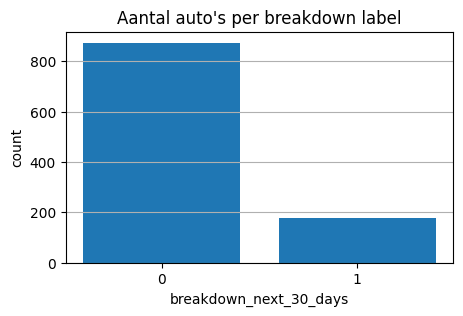

In [9]:
# eenvoudige barplot van de target (aantallen)
counts = df[target].value_counts().sort_index()

plt.figure(figsize=(5,3))
plt.bar(counts.index.astype(str), counts.values)
plt.title("Aantal auto's per breakdown label")
plt.xlabel("breakdown_next_30_days")
plt.ylabel("count")
plt.grid(True, axis="y")
plt.show()


## Univariate: verdelingen van belangrijke numerieke variabelen

We starten met klassiekers die vaak “predictive” zijn:
- `vehicle_age_years`
- `mileage_km`
- `last_service_km_ago`
- `oil_quality_pct`
- `engine_hours`

We bekijken: **describe()** + **histogram** + **boxplot**.


In [10]:
num_cols = [
    "vehicle_age_years", "mileage_km", "engine_hours", "last_service_km_ago",
    "oil_quality_pct", "avg_trip_length_km", "cleanliness_score",
    "driver_satisfaction_score"
]

df[num_cols].describe()


,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,cleanliness_score,driver_satisfaction_score
count,1034.000000,1.033000e+03,1035.000000,1040.000000,1014.000000,1038.000000,995.000000,1037.000000
mean,9.399420,3.639119e+06,4368.929467,10681.075986,60.682779,38.861387,69.393768,6.972183
std,5.752228,2.585818e+07,2214.510223,9341.969609,20.298624,47.968702,15.570872,1.478278
min,0.000000,-1.829042e+02,-50.000000,10.869020,0.000000,1.011100,-13.171570,2.504369
25%,5.000000,8.338616e+04,2773.353090,3374.773323,47.377582,8.187057,58.902723,6.001099
50%,9.000000,1.202357e+05,3967.125562,8085.318122,60.528422,16.788852,69.504547,6.928004
75%,14.000000,1.674871e+05,5432.498224,14455.318280,74.654436,44.308719,79.597898,8.022503
max,20.000000,3.734539e+08,10298.582128,40592.195120,102.548055,201.015553,144.139920,10.291940


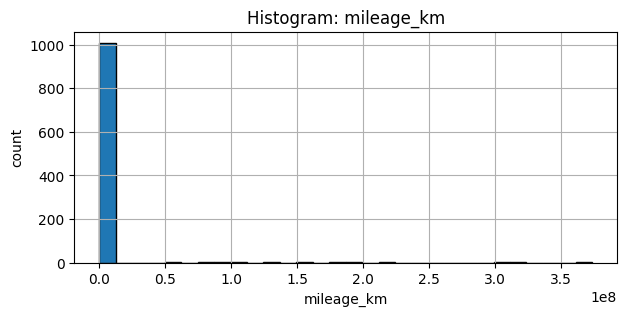

In [11]:
# histograms (1 per keer om overzicht te houden)
col = "mileage_km"
plt.figure(figsize=(7,3))
plt.hist(df[col].dropna(), bins=30, ec="black")
plt.title(f"Histogram: {col}")
plt.xlabel(col)
plt.ylabel("count")
plt.grid(True)
plt.show()


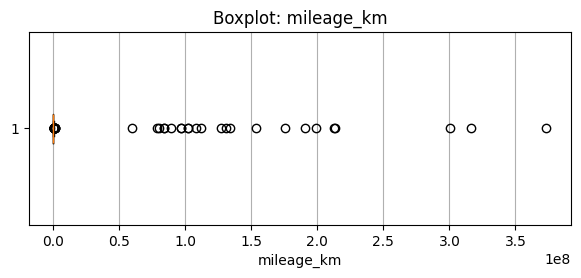

In [12]:
# boxplot (handig om outliers te zien)
col = "mileage_km"
plt.figure(figsize=(7,2.5))
plt.boxplot(df[col].dropna(), vert=False)
plt.title(f"Boxplot: {col}")
plt.xlabel(col)
plt.grid(True, axis="x")
plt.show()


## Bivariate: breakdown-rate per merk (vehicle_brand)

Dit beantwoordt direct jouw voorbeeld: “Fords gaan sneller kapot”.  
We berekenen per merk:
- aantal wagens
- breakdown-rate (= gemiddeld van 0/1)
We sorteren dalend op breakdown-rate.


In [13]:
brand_stats = (
    df.groupby("vehicle_brand")[target]
      .agg(["count", "mean"])
      .rename(columns={"count":"n", "mean":"breakdown_rate"})
      .sort_values("breakdown_rate", ascending=False)
)

brand_stats.head(15)


,n,breakdown_rate
vehicle_brand,,
other,14,0.214286
Volvo,93,0.204301
Ford,194,0.190722
BMW,125,0.184000
Toyota,193,0.181347
Renault,97,0.164948
Volkswagen,143,0.139860
Kia,69,0.101449
Hyundai,101,0.099010


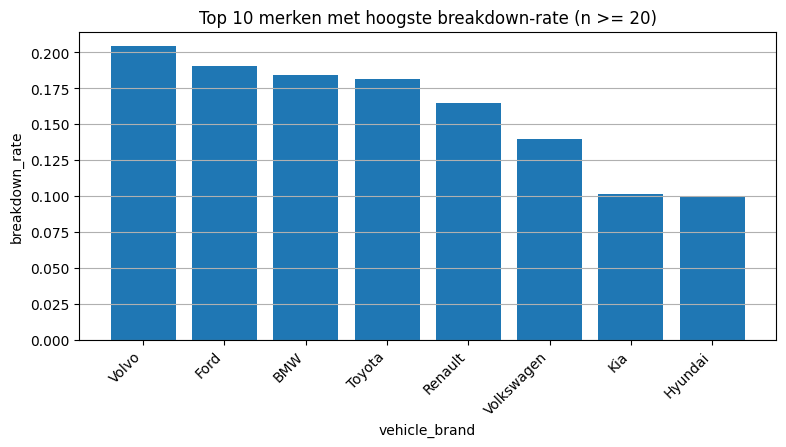

In [14]:
# Plot top 10 brands (met voldoende records)
min_n = 20
top = brand_stats[brand_stats["n"] >= min_n].head(10)

plt.figure(figsize=(9,4))
plt.bar(top.index.astype(str), top["breakdown_rate"].values)
plt.title(f"Top 10 merken met hoogste breakdown-rate (n >= {min_n})")
plt.xlabel("vehicle_brand")
plt.ylabel("breakdown_rate")
plt.xticks(rotation=45, ha="right")
plt.grid(True, axis="y")
plt.show()


## Mileage bins: “meer dan 200.000 km”

We maken een binned kolom voor `mileage_km` zodat je duidelijke drempels krijgt (exam-style interpretatie).
Daarna:
- breakdown-rate per mileage-bin
- breakdown-rate per (brand × mileage-bin) om jouw combo te vinden


In [15]:
# mileage bins (pas gerust aan)
bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, np.inf]
labels = ["0-50k","50-100k","100-150k","150-200k","200-250k","250-300k","300k+"]
df["mileage_bin"] = pd.cut(df["mileage_km"], bins=bins, labels=labels, right=False)

mileage_stats = df.groupby("mileage_bin")[target].agg(["count","mean"]).rename(columns={"count":"n","mean":"breakdown_rate"})
mileage_stats


,n,breakdown_rate
mileage_bin,,
0-50k,62,0.112903
50-100k,327,0.183486
100-150k,301,0.156146
150-200k,165,0.145455
200-250k,67,0.149254
250-300k,42,0.309524
300k+,68,0.220588


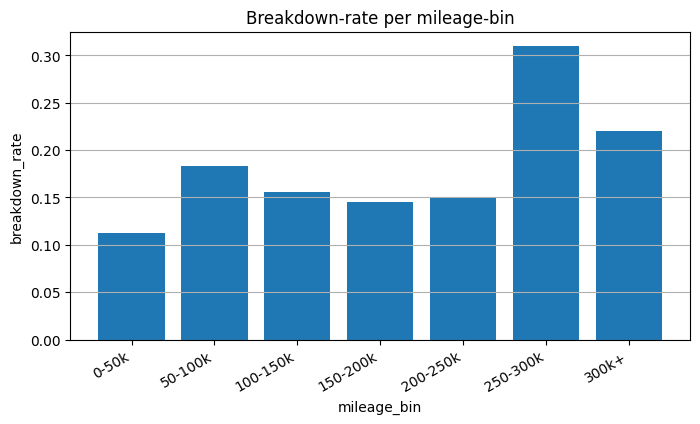

In [16]:
plt.figure(figsize=(8,4))
plt.bar(mileage_stats.index.astype(str), mileage_stats["breakdown_rate"].values)
plt.title("Breakdown-rate per mileage-bin")
plt.xlabel("mileage_bin")
plt.ylabel("breakdown_rate")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y")
plt.show()


In [17]:
# combinatie merk x mileage_bin (zoals jouw voorbeeld)
combo = (
    df.groupby(["vehicle_brand","mileage_bin"])[target]
      .agg(["count","mean"])
      .rename(columns={"count":"n","mean":"breakdown_rate"})
      .reset_index()
)

# filter: genoeg data
combo_f = combo[combo["n"] >= 10].sort_values("breakdown_rate", ascending=False)
combo_f.head(20)


,vehicle_brand,mileage_bin,n,breakdown_rate
13,Ford,300k+,13,0.384615
48,Volkswagen,300k+,10,0.300000
49,Volvo,0-50k,10,0.300000
1,BMW,50-100k,42,0.285714
51,Volvo,100-150k,21,0.285714
...,...,...,...,...
30,Renault,100-150k,27,0.148148
36,Toyota,50-100k,63,0.142857
46,Volkswagen,200-250k,15,0.133333
11,Ford,200-250k,15,0.133333


## Service & oliekwaliteit: duidelijke risicofactoren?

Hypothese (logisch):  
- **meer km sinds laatste service** → hogere breakdown-rate  
- **lagere oil_quality_pct** → hogere breakdown-rate

We bekijken dit met bins (gemakkelijk te interpreteren).


In [18]:
# last_service_km_ago bins
svc_bins = [0, 2000, 5000, 10000, 20000, np.inf]
svc_labels = ["0-2k","2-5k","5-10k","10-20k","20k+"]
df["service_bin"] = pd.cut(df["last_service_km_ago"], bins=svc_bins, labels=svc_labels, right=False)

service_stats = df.groupby("service_bin")[target].agg(["count","mean"]).rename(columns={"count":"n","mean":"breakdown_rate"})
service_stats


,n,breakdown_rate
service_bin,,
0-2k,150,0.173333
2-5k,235,0.165957
5-10k,225,0.137778
10-20k,253,0.138340
20k+,177,0.254237


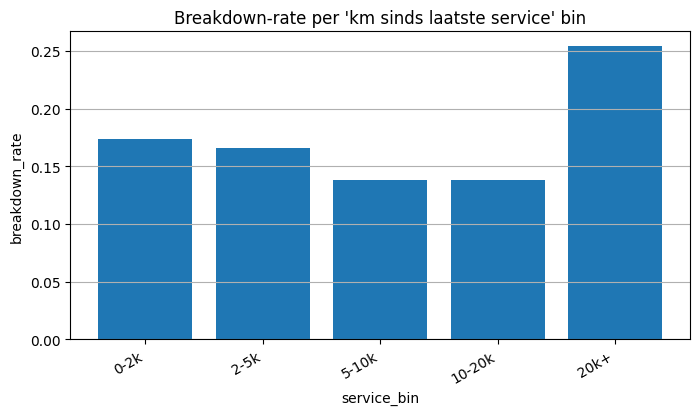

In [19]:
plt.figure(figsize=(8,4))
plt.bar(service_stats.index.astype(str), service_stats["breakdown_rate"].values)
plt.title("Breakdown-rate per 'km sinds laatste service' bin")
plt.xlabel("service_bin")
plt.ylabel("breakdown_rate")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y")
plt.show()


In [20]:
# oil_quality_pct bins
oil_bins = [0, 20, 40, 60, 80, 100.1]
oil_labels = ["0-20","20-40","40-60","60-80","80-100"]
df["oil_bin"] = pd.cut(df["oil_quality_pct"], bins=oil_bins, labels=oil_labels, right=False)

oil_stats = df.groupby("oil_bin")[target].agg(["count","mean"]).rename(columns={"count":"n","mean":"breakdown_rate"})
oil_stats


,n,breakdown_rate
oil_bin,,
0-20,19,0.263158
20-40,137,0.204380
40-60,343,0.180758
60-80,336,0.172619
80-100,166,0.102410


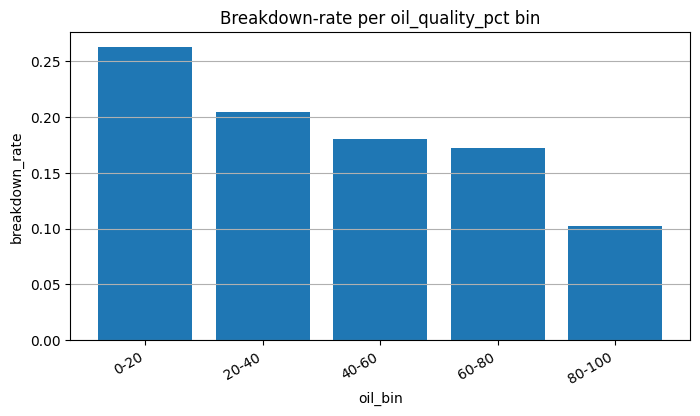

In [21]:
plt.figure(figsize=(8,4))
plt.bar(oil_stats.index.astype(str), oil_stats["breakdown_rate"].values)
plt.title("Breakdown-rate per oil_quality_pct bin")
plt.xlabel("oil_bin")
plt.ylabel("breakdown_rate")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y")
plt.show()


## Categorieën: fuel_type, tyre_type, weather_exposure

Voor categorische variabelen is dit exam-standaard:
- value_counts() (hoe vaak komt het voor?)
- breakdown-rate per categorie


In [22]:
cat_interest = ["fuel_type", "tyre_type", "weather_exposure"]

cat_tables = {}
for c in cat_interest:
    tbl = df.groupby(c)[target].agg(["count","mean"]).rename(columns={"count":"n","mean":"breakdown_rate"}).sort_values("breakdown_rate", ascending=False)
    cat_tables[c] = tbl

cat_tables["fuel_type"].head(20)


,n,breakdown_rate
fuel_type,,
electric,54,0.185185
petrol,435,0.174713
diesel,372,0.166667
hybrid,155,0.161290
other,20,0.150000


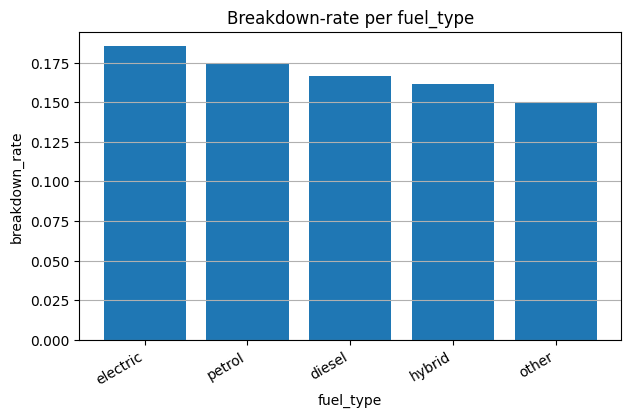

In [23]:
# voorbeeld plot voor fuel_type
tbl = cat_tables["fuel_type"]
plt.figure(figsize=(7,4))
plt.bar(tbl.index.astype(str), tbl["breakdown_rate"].values)
plt.title("Breakdown-rate per fuel_type")
plt.xlabel("fuel_type")
plt.ylabel("breakdown_rate")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y")
plt.show()


## Correlaties (alleen numeriek)

Zoals in de cursus: correlatie ≠ causatie, maar het helpt om relaties te spotten.


In [24]:
num_df = df[num_cols + [target]].copy()
corr = num_df.corr(numeric_only=True)
corr


,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,cleanliness_score,driver_satisfaction_score,breakdown_next_30_days
vehicle_age_years,1.000000,-0.002210,0.015299,0.040071,0.016606,0.042474,0.025936,0.005639,0.138214
mileage_km,-0.002210,1.000000,0.114152,0.060717,0.036886,-0.034124,-0.027715,-0.055603,-0.003028
engine_hours,0.015299,0.114152,1.000000,-0.031101,0.022425,-0.031955,-0.013603,0.066042,0.053000
last_service_km_ago,0.040071,0.060717,-0.031101,1.000000,0.043297,0.046232,0.008769,0.004347,0.067742
oil_quality_pct,0.016606,0.036886,0.022425,0.043297,1.000000,-0.012404,0.017318,-0.019642,-0.083499
avg_trip_length_km,0.042474,-0.034124,-0.031955,0.046232,-0.012404,1.000000,0.019428,0.028570,-0.013303
cleanliness_score,0.025936,-0.027715,-0.013603,0.008769,0.017318,0.019428,1.000000,-0.004824,-0.027467
driver_satisfaction_score,0.005639,-0.055603,0.066042,0.004347,-0.019642,0.028570,-0.004824,1.000000,0.015899
breakdown_next_30_days,0.138214,-0.003028,0.053000,0.067742,-0.083499,-0.013303,-0.027467,0.015899,1.000000


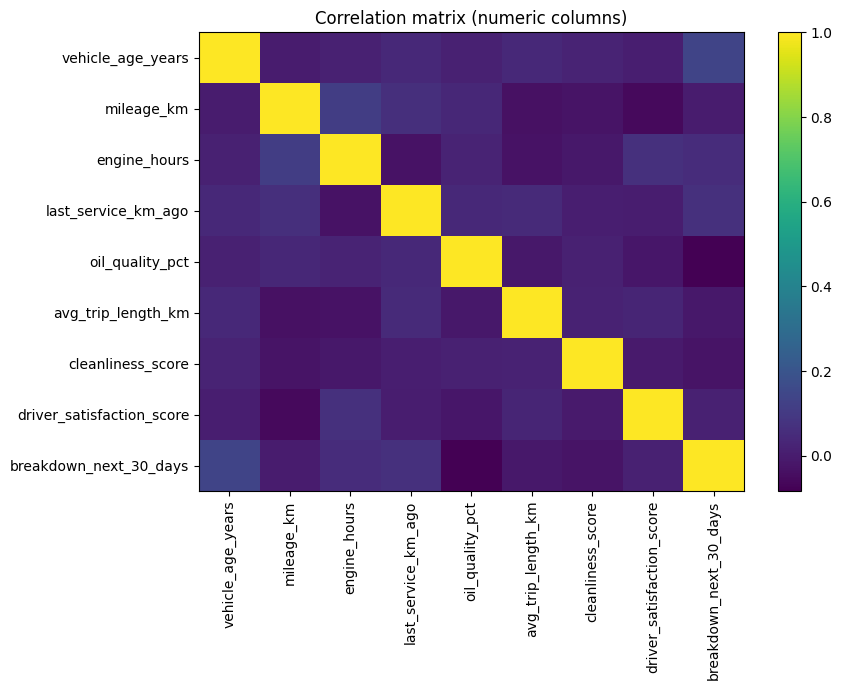

In [25]:
# simpele heatmap via imshow (geen seaborn)
plt.figure(figsize=(9,7))
plt.imshow(corr.values, aspect="auto")
plt.title("Correlation matrix (numeric columns)")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.colorbar()
plt.tight_layout()
plt.show()


## “Wanneer gaat de auto het meeste kapot?” – Top segmenten

We definiëren een **segment** als combinatie van enkele sterke factoren (voorbeeld):
- hoge mileage (>= 200k)
- oude auto (>= 8 jaar)  *(drempel kan je aanpassen)*
- merk

We maken een tabel met breakdown-rate per segment en tonen de top.


In [26]:
# drempels (pas aan indien nodig)
df["is_high_mileage"] = df["mileage_km"] >= 200_000
df["is_old"] = df["vehicle_age_years"] >= 8

seg = (
    df.groupby(["vehicle_brand","is_high_mileage","is_old"])[target]
      .agg(["count","mean"])
      .rename(columns={"count":"n","mean":"breakdown_rate"})
      .reset_index()
)

# focus op segmenten met genoeg data
seg_f = seg[seg["n"] >= 10].sort_values("breakdown_rate", ascending=False)
seg_f.head(25)


,vehicle_brand,is_high_mileage,is_old,n,breakdown_rate
15,Kia,True,True,12,0.333333
29,Volvo,False,True,40,0.275000
6,Ford,True,False,15,0.266667
7,Ford,True,True,19,0.263158
1,BMW,False,True,58,0.241379
...,...,...,...,...,...
0,BMW,False,False,45,0.088889
12,Kia,False,False,26,0.076923
20,Toyota,False,False,64,0.062500
13,Kia,False,True,27,0.037037


## 4) Interpret: wat nemen we mee naar het predictiemodel?

Schrijf (kort) jouw **findings** en **hypotheses** uit.

Voorbeelden die je in je verslag kan zetten:
- *Finding:* “Merken A/B hebben hogere breakdown-rate dan gemiddeld.”  
- *Finding:* “Breakdown-rate stijgt vanaf ~200k km.”  
- *Hypothese:* “Slechte oil_quality + veel km sinds service veroorzaakt meer breakdown.”  
- *Hypothese:* “Oude + high-mileage auto’s in bepaalde merken vormen het hoogste risico.”  

➡️ In de volgende stap (model) ga je dit testen met bv. logistic regression / tree-based model.


In [27]:
# Extra: snelle tabel met overall baseline en een paar highlights
summary = {
    "rows": df.shape[0],
    "cols": df.shape[1],
    "baseline_breakdown_rate": df[target].mean(),
    "top_brands_by_rate (n>=20)": brand_stats[brand_stats["n"]>=20].head(5).to_dict(),
    "mileage_bin_rates": mileage_stats["breakdown_rate"].to_dict(),
    "service_bin_rates": service_stats["breakdown_rate"].to_dict(),
    "oil_bin_rates": oil_stats["breakdown_rate"].to_dict(),
}
summary


{'rows': 1050,
 'cols': 19,
 'baseline_breakdown_rate': np.float64(0.1676190476190476),
 'top_brands_by_rate (n>=20)': {'n': {'Volvo': 93,
   'Ford': 194,
   'BMW': 125,
   'Toyota': 193,
   'Renault': 97},
  'breakdown_rate': {'Volvo': 0.20430107526881722,
   'Ford': 0.19072164948453607,
   'BMW': 0.184,
   'Toyota': 0.18134715025906736,
   'Renault': 0.16494845360824742}},
 'mileage_bin_rates': {'0-50k': 0.11290322580645161,
  '50-100k': 0.1834862385321101,
  '100-150k': 0.15614617940199335,
  '150-200k': 0.14545454545454545,
  '200-250k': 0.14925373134328357,
  '250-300k': 0.30952380952380953,
  '300k+': 0.22058823529411764},
 'service_bin_rates': {'0-2k': 0.17333333333333334,
  '2-5k': 0.16595744680851063,
  '5-10k': 0.13777777777777778,
  '10-20k': 0.1383399209486166,
  '20k+': 0.2542372881355932},
 'oil_bin_rates': {'0-20': 0.2631578947368421,
  '20-40': 0.20437956204379562,
  '40-60': 0.18075801749271136,
  '60-80': 0.17261904761904762,
  '80-100': 0.10240963855421686}}